# AI Fundamentals: Models, Data, Training, and Inference

**Learning objective:** use a tiny, inspectable Python model to distinguish an algorithm from a model, features from labels, parameters from input data, and training from inference.

All data in this notebook is **synthetic**. The networking examples are educational and do not connect to devices or make operational diagnoses.

## Prerequisites

- Read `notes/01-AI-Fundamentals.md` through its first section.
- Python variables, lists, functions, and basic arithmetic.
- Basic idea of a table with columns and rows.
- NumPy and Matplotlib, installed in the selected Jupyter kernel (listed in `requirements.txt`).

No API key, internet connection, GPU, cloud service, or device access is needed.

## Learning objectives

After running this notebook, you should be able to:

1. Identify input features and target labels in a small dataset.
2. Use a simple prediction rule and explain why it is not automatically a trained model.
3. Fit a simple linear model by minimizing a loss with a transparent loop.
4. Distinguish parameter values from input values and compare training with inference.
5. Plot training examples, fitted predictions, and loss over iterations.
6. Debug a deliberate Python error and test a read-only synthetic network example.

## Concept explanation: recipe, examples, fitted result

An **algorithm** is a recipe or procedure. A **dataset** is a collection of examples. A **feature** is an input measurement. A **label** is the target answer provided for an example. **Training** uses examples and a method to choose model parameters; **inference** applies the fitted model to new input.

For this lesson, use a straight-line model:

`prediction = weight × feature + bias`

`weight` and `bias` are **parameters**—values the fitting procedure can adjust. The `feature` is an input measurement. `loss` is a number measuring prediction error according to a selected formula. This is a deliberately small example, not a useful production fault detector.

## Visual explanation

Each dot below will represent one labeled training example: horizontal position is the feature, vertical position is its target label. The line is the model's prediction for possible feature values. Training tries to choose a line that makes prediction errors small under its loss objective.

```text
label ↑          ● example
      |       ●  /  fitted model prediction
      |   ●   /
      +----------------→ feature
```

A line close to the dots does not prove that the relationship is causal, complete, or useful outside these synthetic examples.

## Environment setup

NumPy provides convenient numeric arrays and Matplotlib creates the plot. These are local packages; no installation happens automatically. The small training loop below is written in plain Python so the fitting steps remain visible.

In [1]:
from __future__ import annotations

import matplotlib.pyplot as plt
import numpy as np

print("NumPy:", np.__version__)
print("Matplotlib:", plt.matplotlib.__version__)

NumPy: 2.3.5
Matplotlib: 3.10.8


**Input → processing → output:** imports load the installed libraries; the version values are input from the local environment; `print` displays the versions. If an import fails with `ModuleNotFoundError`, select the intended notebook kernel and install the missing package there, then restart the kernel.

## Level 1 — Very simple: a fixed prediction rule

First apply chosen parameters directly. This demonstrates inference-like calculation, but there is no training yet because the values are supplied by us.

In [2]:
feature_value = 10.0
weight = 2.0
bias = 1.0
prediction = weight * feature_value + bias

print("Input feature:", feature_value)
print("Chosen weight:", weight)
print("Chosen bias:", bias)
print("Prediction:", prediction)
assert prediction == 21.0

Input feature: 10.0
Chosen weight: 2.0
Chosen bias: 1.0
Prediction: 21.0


### Examine the output

**Expected output:** feature `10.0`, weight `2.0`, bias `1.0`, prediction `21.0`. Python calculates `2 × 10 + 1`. Notice that the prediction changes if the feature or either parameter changes. No examples were used to choose the parameters, so this is not evidence that the values fit a real task.

## Level 2 — Beginner: examples, features, and labels

Here the feature is a synthetic count of CRC errors per minute, and the label is a synthetic numeric score. The score is provided as a teaching target; it is not a real probability or diagnosis.

In [3]:
crc_errors_per_minute = [0.0, 1.0, 2.0, 3.0, 4.0, 5.0]
synthetic_investigation_score = [1.0, 3.0, 5.0, 7.0, 9.0, 11.0]

print("Feature examples:", crc_errors_per_minute)
print("Label examples:  ", synthetic_investigation_score)
assert len(crc_errors_per_minute) == len(synthetic_investigation_score)

Feature examples: [0.0, 1.0, 2.0, 3.0, 4.0, 5.0]
Label examples:   [1.0, 3.0, 5.0, 7.0, 9.0, 11.0]


The two lists line up by position: feature at index `i` belongs to label at index `i`. Here `crc_errors_per_minute` is the input feature and `synthetic_investigation_score` is the label. The length assertion catches a common data error: examples and answers must be paired. If records are reordered independently, the pairs become wrong even if both lists have the same length.

## Visualize the training data before fitting

We plot the synthetic feature/label pairs. Visualization is a useful data check, but a visible pattern does not establish causation or operational reliability.

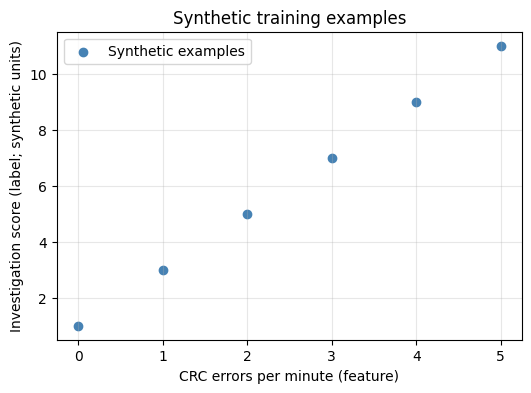

In [4]:
plt.figure(figsize=(6, 4))
plt.scatter(crc_errors_per_minute, synthetic_investigation_score, color="steelblue", label="Synthetic examples")
plt.title("Synthetic training examples")
plt.xlabel("CRC errors per minute (feature)")
plt.ylabel("Investigation score (label; synthetic units)")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

### How to read this graph

- **X-axis:** synthetic CRC count, the input feature.
- **Y-axis:** synthetic score, the target label.
- **Points:** paired examples, not live device measurements.
- **Pattern:** the points rise in a straight line because we constructed them that way.
- **Useful for:** checking values, ranges, and obvious relationships before fitting.
- **Do not conclude:** that CRC counts alone cause incidents or can explain a production outage.

## Level 3 — Intermediate: train a model with a visible algorithm

We fit `prediction = weight × feature + bias` by trying a grid of candidate parameter pairs and selecting the pair with the smallest **mean squared error (MSE)**. MSE squares each prediction error, then averages the squared errors. This grid-search procedure is our algorithm for this tiny lesson; the selected `best_weight` and `best_bias` form the fitted model.

In [5]:
def predict_linear(feature: float, weight: float, bias: float) -> float:
    """Return a line's prediction for one numeric feature."""
    return weight * feature + bias


def mean_squared_error(actual: list[float], predicted: list[float]) -> float:
    """Calculate average squared prediction error for paired numbers."""
    if len(actual) == 0:
        raise ValueError("actual and predicted values must not be empty")
    if len(actual) != len(predicted):
        raise ValueError("actual and predicted values must have the same length")
    squared_errors = [(target - guess) ** 2 for target, guess in zip(actual, predicted)]
    return sum(squared_errors) / len(squared_errors)


candidate_weights = [0.0, 1.0, 2.0, 3.0]
candidate_biases = [0.0, 1.0, 2.0]
best_model = {"weight": None, "bias": None, "loss": float("inf")}

for candidate_weight in candidate_weights:
    for candidate_bias in candidate_biases:
        candidate_predictions = [
            predict_linear(value, candidate_weight, candidate_bias)
            for value in crc_errors_per_minute
        ]
        candidate_loss = mean_squared_error(
            synthetic_investigation_score, candidate_predictions
        )
        if candidate_loss < best_model["loss"]:
            best_model = {
                "weight": candidate_weight,
                "bias": candidate_bias,
                "loss": candidate_loss,
            }

print("Fitted parameters:", best_model)
assert best_model == {"weight": 2.0, "bias": 1.0, "loss": 0.0}

Fitted parameters: {'weight': 2.0, 'bias': 1.0, 'loss': 0.0}


### Explain the code and output

`predict_linear` applies the current parameters. `mean_squared_error` checks input validity, pairs targets and predictions with `zip`, squares each difference, and averages them. The nested loops try every candidate weight/bias combination. `best_model` is a dictionary holding the best parameters and loss found so far. Because the synthetic labels were created by `score = 2 × errors + 1`, the search finds weight `2.0`, bias `1.0`, and loss `0.0`.

A zero training loss here means the chosen line exactly matches this tiny constructed dataset. It does **not** guarantee a real-world model will generalize.

## Visualize the fitted model

The line shows the model's output for a range of feature values. Points remain the supplied examples. The axes and units are the same as the previous plot.

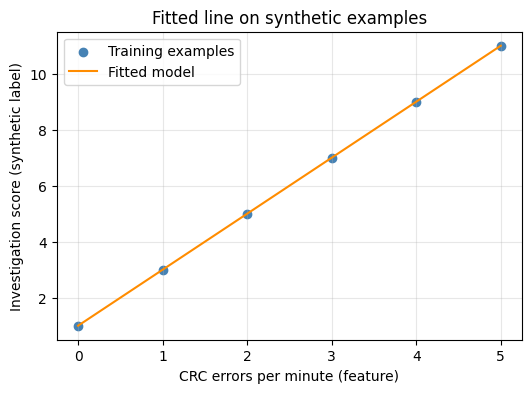

In [6]:
feature_line = np.linspace(0, 5, 100)
prediction_line = [
    predict_linear(value, best_model["weight"], best_model["bias"])
    for value in feature_line
]

plt.figure(figsize=(6, 4))
plt.scatter(crc_errors_per_minute, synthetic_investigation_score, color="steelblue", label="Training examples")
plt.plot(feature_line, prediction_line, color="darkorange", label="Fitted model")
plt.title("Fitted line on synthetic examples")
plt.xlabel("CRC errors per minute (feature)")
plt.ylabel("Investigation score (synthetic label)")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

Notice the orange line passes through the blue points because the sample values were generated from exactly that line. `np.linspace` supplies many evenly spaced x-values so the plotted line looks continuous. If the labels included noise or a curve, the line would not pass through every point. A graph should help inspect fit, not replace held-out evaluation.

## Training loss and parameter meaning

Loss measures mismatch for a candidate model. We compare a few possible weights while keeping the bias fixed at `1`. This isolates how the weight changes the error.

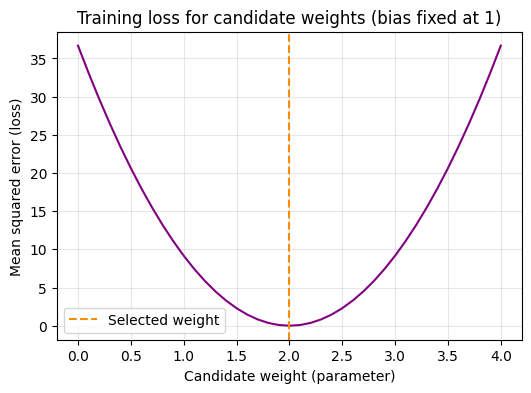

Minimum loss: 0.0
Weight at minimum: 2.0


In [7]:
weight_values = np.linspace(0, 4, 41)
loss_values = [
    mean_squared_error(
        synthetic_investigation_score,
        [predict_linear(value, candidate_weight, 1.0) for value in crc_errors_per_minute],
    )
    for candidate_weight in weight_values
]

plt.figure(figsize=(6, 4))
plt.plot(weight_values, loss_values, color="purple")
plt.axvline(best_model["weight"], color="darkorange", linestyle="--", label="Selected weight")
plt.title("Training loss for candidate weights (bias fixed at 1)")
plt.xlabel("Candidate weight (parameter)")
plt.ylabel("Mean squared error (loss)")
plt.grid(alpha=0.3)
plt.legend()
plt.show()
print("Minimum loss:", min(loss_values))
print("Weight at minimum:", float(weight_values[int(np.argmin(loss_values))]))

### Interpret the loss graph

- **X-axis:** candidate weight parameter.
- **Y-axis:** training MSE loss.
- **Purple curve:** error for each candidate weight, with bias fixed.
- **Orange dashed line:** the selected weight.
- The lowest point occurs at weight `2`, because that reproduces the constructed labels.
- This plot is useful for seeing that training searches for parameters with lower loss.
- Do not conclude that lower training loss always means better predictions on unseen data; that requires validation/testing.

## Training versus inference: hold out a new input

The parameter search has finished. Inference uses the fitted parameters as-is to predict for a new synthetic feature value.

In [8]:
new_crc_count = 6.0
inference_score = predict_linear(
    new_crc_count,
    best_model["weight"],
    best_model["bias"],
)

print("Inference input (synthetic CRC count):", new_crc_count)
print("Fitted parameters used:", {"weight": best_model["weight"], "bias": best_model["bias"]})
print("Model output (synthetic score):", inference_score)
assert inference_score == 13.0

Inference input (synthetic CRC count): 6.0
Fitted parameters used: {'weight': 2.0, 'bias': 1.0}
Model output (synthetic score): 13.0


**Input:** a new count of `6`. **Processing:** apply `2 × 6 + 1` using the fitted parameters without changing them. **Output:** score `13.0`. This illustrates inference, not a verified fault probability. The input is beyond the largest training feature (`5`), so it also illustrates extrapolation; in real systems, predictions outside training ranges deserve caution.

## Modify the example

Change one value in `synthetic_investigation_score`, rerun the data and fitting cells, and observe how the selected parameters and loss change. Then change `new_crc_count` and rerun only the inference cell. The first change affects training data and may refit the model; the second changes the inference input but leaves the fitted model unchanged.

## Break the code intentionally, then debug it

The following broken call uses lists of different lengths. It is wrapped so the notebook can continue while displaying the expected failure.

In [9]:
try:
    mean_squared_error([1.0, 2.0], [1.0])
except ValueError as error:
    print(type(error).__name__ + ":", error)

fixed_loss = mean_squared_error([1.0, 2.0], [1.0, 2.5])
print("Loss after supplying paired values:", fixed_loss)
assert fixed_loss == 0.125

ValueError: actual and predicted values must have the same length
Loss after supplying paired values: 0.125


### Read the error

The first call raises `ValueError: actual and predicted values must have the same length`. This is an intentional validation error, not a mysterious Python failure. If we had skipped the explicit length check, `zip` would silently stop at the shorter list and ignore an example. The fix supplies one prediction per target; the squared errors are `0` and `0.25`, whose mean is `0.125`.

## Network engineering example: read-only synthetic records

Now use small dictionary records resembling telemetry summaries. The function validates required fields and calculates a score using the fitted demonstration model. It does not connect to devices, change configuration, or claim to identify root cause.

In [10]:
synthetic_interface_records = [
    {"device": "router-a", "interface": "Gi0/0/0/1", "crc_errors_per_minute": 0.0},
    {"device": "switch-b", "interface": "Ethernet2", "crc_errors_per_minute": 3.0},
]

def score_interface_record(record: dict[str, str | float]) -> dict[str, str | float]:
    """Return a synthetic score for a supplied read-only interface record."""
    required_fields = {"device", "interface", "crc_errors_per_minute"}
    missing_fields = required_fields - record.keys()
    if missing_fields:
        raise ValueError(f"record is missing required fields: {sorted(missing_fields)}")
    crc_count = float(record["crc_errors_per_minute"])
    score = predict_linear(crc_count, best_model["weight"], best_model["bias"])
    return {
        "device": str(record["device"]),
        "interface": str(record["interface"]),
        "synthetic_score": score,
        "evidence": f"supplied CRC count: {crc_count}",
        "diagnosis": "not determined by this demonstration",
    }

network_findings = [score_interface_record(record) for record in synthetic_interface_records]
for finding in network_findings:
    print(finding)

try:
    score_interface_record({"device": "router-c"})
except ValueError as error:
    print("Invalid-record check:", error)

assert len(network_findings) == 2
assert network_findings[0]["synthetic_score"] == 1.0

{'device': 'router-a', 'interface': 'Gi0/0/0/1', 'synthetic_score': 1.0, 'evidence': 'supplied CRC count: 0.0', 'diagnosis': 'not determined by this demonstration'}
{'device': 'switch-b', 'interface': 'Ethernet2', 'synthetic_score': 7.0, 'evidence': 'supplied CRC count: 3.0', 'diagnosis': 'not determined by this demonstration'}
Invalid-record check: record is missing required fields: ['crc_errors_per_minute', 'interface']


### Explain input, processing, and output

- **Input:** synthetic dictionaries with device, interface, and CRC count.
- **Processing:** check required keys, convert the counter to a number, and call the already-fitted demonstration model.
- **Output:** a structured dictionary carrying the score and the observed input evidence, plus an explicit statement that the demo does not determine diagnosis.
- **Failure behavior:** a missing required field raises a clear `ValueError`; it does not silently label the device healthy.
- **Real-project connection:** an approved telemetry collector could provide read-only records, while separate validated logic and engineer review determine appropriate next steps.

## Practice exercises

### Beginner
1. Change `feature_value` to `4` in the fixed-rule example. What is the new prediction?
2. Add one paired synthetic feature and label to the two lists. Confirm their lengths still match.
3. In the fitted equation, identify the input feature, parameters, and output.

### Intermediate
4. Modify `mean_squared_error` to return the largest absolute error instead of MSE, using a new clearly named function.
5. Add a candidate weight to the grid and explain whether the selected model or loss changes.

### Advanced
6. Add a model evaluation check that refuses to score values outside the training feature range. Explain why extrapolation may be risky.

### Network automation
7. Add a synthetic interface with a negative CRC count. Extend `score_interface_record` to reject negative counters, then test both valid and invalid records. Keep the function local and read-only.

## Exercise solutions

Try the exercises first. The following cell gives sample solutions; it uses only synthetic data and local calculations.

In [11]:
# 1
print("1 prediction:", weight * 4 + bias)

# 2
features_with_extra = crc_errors_per_minute + [6.0]
labels_with_extra = synthetic_investigation_score + [13.0]
assert len(features_with_extra) == len(labels_with_extra)
print("2 paired examples:", len(features_with_extra))

# 3
print("3: feature = x; parameters = weight and bias; output = prediction")

# 4
def maximum_absolute_error(actual: list[float], predicted: list[float]) -> float:
    """Return the largest absolute error for paired non-empty values."""
    if len(actual) == 0 or len(actual) != len(predicted):
        raise ValueError("provide equally sized, non-empty lists")
    return max(abs(target - guess) for target, guess in zip(actual, predicted))

print("4 maximum absolute error:", maximum_absolute_error([1, 2], [1, 2.5]))

# 5
expanded_weights = candidate_weights + [2.5]
print("5 candidate weight count:", len(expanded_weights))
print("The exact fitted weight remains 2.0 because that is already in the grid and gives zero loss.")

# 6
training_min = min(crc_errors_per_minute)
training_max = max(crc_errors_per_minute)
def predict_within_training_range(value: float) -> float:
    """Predict only when the feature is inside the observed training range."""
    if not training_min <= value <= training_max:
        raise ValueError("feature is outside the training range")
    return predict_linear(value, best_model["weight"], best_model["bias"])

print("6 in-range prediction:", predict_within_training_range(4.0))

# 7
def validate_crc_count(value: float) -> float:
    """Convert a counter to float and reject invalid negative values."""
    numeric_value = float(value)
    if numeric_value < 0:
        raise ValueError("CRC count must not be negative")
    return numeric_value

assert validate_crc_count(3) == 3.0
try:
    validate_crc_count(-1)
except ValueError as error:
    print("7 invalid counter check:", error)

1 prediction: 9.0
2 paired examples: 7
3: feature = x; parameters = weight and bias; output = prediction
4 maximum absolute error: 0.5
5 candidate weight count: 5
The exact fitted weight remains 2.0 because that is already in the grid and gives zero loss.
6 in-range prediction: 9.0
7 invalid counter check: CRC count must not be negative


### Solution notes

The first result is `9.0` using weight `2` and bias `1`. Adding a paired item keeps feature/label alignment intact. Maximum absolute error differs from MSE: it reports the single largest miss and is more sensitive to one extreme error. Adding candidate weights does not improve a zero-loss fit on these constructed labels. The range guard demonstrates one way to reject extrapolation, though production handling needs domain-specific policies. Negative counters are invalid for this example and should fail clearly.

## Mini-project: inspect a tiny training-to-inference lifecycle

Create a compact report containing training example count, selected parameters, training loss, and one inference result. This report describes the demonstration only; it must not be presented as an operational diagnosis.

In [12]:
course_model_report = {
    "data_kind": "synthetic",
    "training_examples": len(crc_errors_per_minute),
    "feature_name": "CRC errors per minute",
    "label_name": "synthetic investigation score",
    "algorithm": "grid search over candidate weight and bias values",
    "fitted_parameters": {
        "weight": best_model["weight"],
        "bias": best_model["bias"],
    },
    "training_mse": best_model["loss"],
    "inference_input": new_crc_count,
    "inference_output": inference_score,
    "operational_diagnosis": None,
}

for key, value in course_model_report.items():
    print(f"{key}: {value}")
assert course_model_report["data_kind"] == "synthetic"
assert course_model_report["operational_diagnosis"] is None

data_kind: synthetic
training_examples: 6
feature_name: CRC errors per minute
label_name: synthetic investigation score
algorithm: grid search over candidate weight and bias values
fitted_parameters: {'weight': 2.0, 'bias': 1.0}
training_mse: 0.0
inference_input: 6.0
inference_output: 13.0
operational_diagnosis: None


The report makes the lifecycle explicit: what data was used, which algorithm was used, what parameters were selected, how training fit was summarized, and what inference produced. It also records that no operational diagnosis was made. In a real system, add dataset version, model version, evaluation on held-out data, and approval/audit details.

## Key takeaways

1. Features are inputs; labels are example targets.
2. An algorithm is a fitting procedure; the fitted model contains selected parameter values.
3. Weights and bias are parameters in the simple linear model.
4. Loss quantifies mismatch according to a selected formula.
5. Training chooses parameters; inference uses them without retraining.
6. Graphs can expose fit patterns but do not establish causality.
7. Synthetic examples teach mechanics but do not validate operational predictions.
8. Validate inputs and fail explicitly when data is missing or malformed.

## Restart Kernel and Run All verification checklist

- [ ] Select the intended Python kernel.
- [ ] Restart the kernel and run every cell from top to bottom.
- [ ] Confirm both plots render with readable labels and legends.
- [ ] Confirm the fitted synthetic weight is `2.0`, bias is `1.0`, and training loss is `0.0`.
- [ ] Confirm inference on synthetic input `6.0` yields score `13.0` and is described as extrapolation.
- [ ] Confirm the deliberate length mismatch prints a clear `ValueError` and the fixed example yields loss `0.125`.
- [ ] Confirm the network example uses only synthetic records and makes no device changes or diagnosis.
- [ ] Confirm all solution cells and assertions complete.

**Completion summary:** this notebook demonstrates data → fitting algorithm → parameters/model → inference, with visible outputs, plots, input validation, and safe synthetic networking examples.